# Pass destination choice

The transition model assigns scores to candidate destinations and normalizes them as one choice distribution. A heatmap makes the destination probabilities inspectable. **own derivation**

## Model and inputs

For one state, the XGBoost transition model scores each candidate grid cell from pass geometry, carrier speed, target pitch control, expected threat, pressure-line indices, and drive risk. The wrapper applies a numerically stable softmax across candidate cells: p_k=exp(z_k−max z)/Σ_l exp(z_l−max z). This is a top-one choice distribution over destinations. The training code uses grouped softmax cross-entropy over candidate destinations; ListNet is a methodological reference for listwise ranking, not a claim that every detail of this implementation is identical [@cao2007listnet]. Elapsed time is not used as an input.

## Usage and visual

The following code uses deterministic synthetic inputs. Any printed quantities and figure values are computed by this cell; no match-level data are embedded.

## Component scope and model limits

Feature list and softmax are read from `PRESS/utils/transition.py`; **own derivation**. Listwise ranking context [@cao2007listnet].

The softmax is conditional on the candidate destinations supplied for the current state. It does not itself represent the pass-versus-drive choice, and its values can change when the candidate set changes. **model scope**


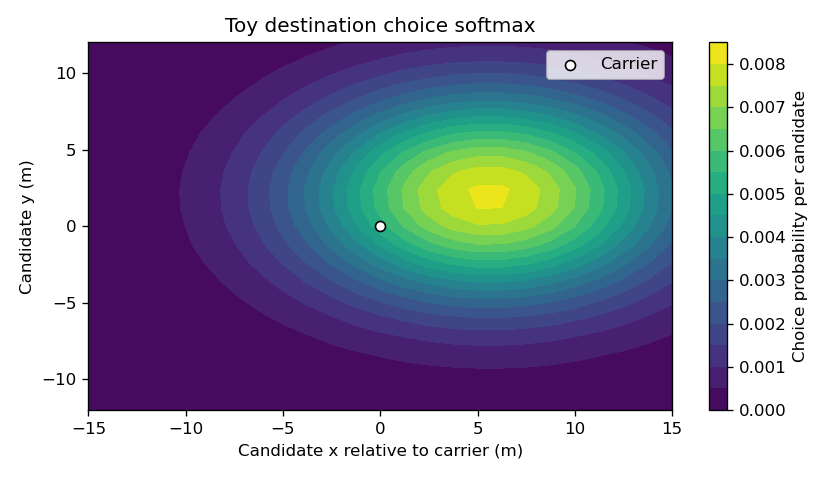

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
# Deterministic toy candidate scores; this demonstrates the wrapper's softmax normalization.
x,y=np.meshgrid(np.linspace(-15,15,25),np.linspace(-12,12,21)); score=-(x-4)**2/90-(y-2)**2/45+0.035*x
flat=score.ravel(); e=np.exp(flat-flat.max()); p=e/e.sum(); field=p.reshape(score.shape)
fig,ax=plt.subplots(figsize=(7,4)); im=ax.contourf(x,y,field,levels=18,cmap="viridis"); fig.colorbar(im,ax=ax,label="Choice probability per candidate"); ax.scatter([0],[0],c="white",edgecolor="black",label="Carrier"); ax.set(xlabel="Candidate x relative to carrier (m)",ylabel="Candidate y (m)",title="Toy destination choice softmax"); ax.legend(); fig.tight_layout()
out=Path("figures/vignette_03_transition.png"); out.parent.mkdir(exist_ok=True); fig.savefig(out,dpi=150); fig.savefig(out.with_suffix(".svg"))